In [1]:
%pip install darts

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.0/70.0 kB 5.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 907.7/907.7 kB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.4/417.4 kB 33.1 MB/s eta 0:00:00


In [2]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.dataprocessing.transformers import Scaler
from darts.models import (RandomForest, LinearRegressionModel, LightGBMModel,
                          AutoARIMA, NBEATSModel)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [3]:
SEED = 0
DATASET_NAME = "daily_waste_output_Dehiwala"
TEST_START   = "2015-02-01"
DATA_FILE    = "daily_waste_output_Dehiwala"        # output of the Moratuwa imputation notebook
OUTPUT_DIR   = f"results_{DATASET_NAME}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
df = pd.read_csv('daily_waste_output_Dehiwala.csv')

In [5]:
df.head(5)

,ticket_date,net_weight_kg
0,2012-01-01 00:00:00+00:00,90418.0
1,2012-01-02 00:00:00+00:00,123010.0
2,2012-01-03 00:00:00+00:00,128330.0
3,2012-01-04 00:00:00+00:00,79430.0
4,2012-01-05 00:00:00+00:00,121320.0


In [6]:
df.shape

(1461, 2)

In [7]:
df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None)

In [8]:
df = df[["ticket_date", "net_weight_kg"]].sort_values("ticket_date").reset_index(drop=True)

In [9]:
series = TimeSeries.from_dataframe(df, time_col="ticket_date", value_cols="net_weight_kg", freq="D")

In [10]:
gaps = int((df["ticket_date"].diff().dropna() != pd.Timedelta(days=1)).sum())
print("Date gaps (should be 0):", gaps, "| blank values (should be 0):", int(df["net_weight_kg"].isna().sum()))

Date gaps (should be 0): 0 | blank values (should be 0): 0


In [11]:
split = int((df["ticket_date"] < pd.Timestamp(TEST_START)).sum())
train_dates = pd.DatetimeIndex(df["ticket_date"][:split])
test_dates  = pd.DatetimeIndex(df["ticket_date"][split:])
train_vals  = df["net_weight_kg"].to_numpy(dtype=float)[:split]
test_vals   = df["net_weight_kg"].to_numpy(dtype=float)[split:]
print("Train days:", len(train_vals), "| Test days:", len(test_vals))

Train days: 1127 | Test days: 334


In [12]:
def scores(actual, pred):
    out = {"rmse": float(np.sqrt(mean_squared_error(actual, pred))),
           "mae":  float(mean_absolute_error(actual, pred)),
           "r2":   float(r2_score(actual, pred))}
    if np.all(actual != 0):                       # MAPE breaks when a real value is 0
        out["mape_%"] = float(np.mean(np.abs((actual - pred) / actual)) * 100)
    return out

def forecast_multi(make_model, tr_dates, tr_vals, future_dates):
    """One model per weekday. Each model sees only that weekday's values, one per week."""
    lo, hi = tr_vals.min(), tr_vals.max()
    scaled = (tr_vals - lo) / (hi - lo)           # min-max scaling, fitted on the training part only
    n_weeks = len(future_dates) // 7 + 1
    train_weekday = np.asarray(tr_dates.dayofweek)

    pred_by_weekday = {}
    for d in range(7):
        model = make_model()
        model.fit(TimeSeries.from_values(scaled[train_weekday == d]))
        pred_by_weekday[d] = model.predict(n=n_weeks).values().flatten() * (hi - lo) + lo

    used = {d: 0 for d in range(7)}               # the k-th future Monday gets Monday model's k-th forecast
    out = []
    for d in future_dates.dayofweek:
        out.append(pred_by_weekday[d][used[d]])
        used[d] += 1
    return np.array(out)

all_results, all_preds = {}, {}

def run_model(label, make_model, grid):
    """grid = list of settings dictionaries; make_model(settings) returns a new model."""
    horizon = len(test_vals)
    tm_dates, tm_vals = train_dates[:-horizon], train_vals[:-horizon]      # earlier part of training
    v_dates,  v_vals  = train_dates[-horizon:], train_vals[-horizon:]      # validation block

    best_params, best_err = None, np.inf
    for params in grid:                            # choose settings on the validation block
        try:
            pred = forecast_multi(lambda: make_model(params), tm_dates, tm_vals, v_dates)
            err = float(np.sqrt(mean_squared_error(v_vals, pred)))
            print(label, params, "-> validation RMSE", round(err, 1))
            if err < best_err:
                best_params, best_err = params, err
        except Exception as e:
            print("Failed:", label, params, "|", str(e)[:100])
    if best_params is None:
        raise ValueError(f"All settings failed for {label}")

    # refit on the full training part, test once
    pred = forecast_multi(lambda: make_model(best_params), train_dates, train_vals, test_dates)
    name = "multi_" + label + "_" + "_".join(f"{k}-{v}" for k, v in best_params.items())
    all_results[label] = {"model_name": name, **scores(test_vals, pred)}
    all_preds[label] = pred
    print("DONE:", name, all_results[label], "\n")

# Random Forest

In [13]:
grid = [{"lags": l, "n_estimators": n, "max_depth": d}
        for l in [4, 8, 12, 24] for n in [10, 100] for d in [4, 8]]

run_model("rf",
          lambda p: RandomForest(lags=p["lags"], n_estimators=p["n_estimators"],
                                 max_depth=p["max_depth"], random_state=SEED),
          grid)

rf {'lags': 4, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 27310.4


rf {'lags': 4, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 29298.9


rf {'lags': 4, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 27691.3


rf {'lags': 4, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 28942.9


rf {'lags': 8, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 25227.6


...

rf {'lags': 24, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 24738.3


rf {'lags': 24, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 24343.9


rf {'lags': 24, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 24435.6


rf {'lags': 24, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 24268.7


DONE: multi_rf_lags-24_n_estimators-100_max_depth-8 {'model_name': 'multi_rf_lags-24_n_estimators-100_max_depth-8', 'rmse': 35504.430308458046, 'mae': 21975.91980407968, 'r2': 0.7909303493487516} 



## Linear Regression

In [14]:
run_model("lr", lambda p: LinearRegressionModel(lags=p["lags"]),
          [{"lags": l} for l in [1, 4, 8, 12, 24]])

lr {'lags': 1} -> validation RMSE 26617.5
lr {'lags': 4} -> validation RMSE 26338.7
lr {'lags': 8} -> validation RMSE 25946.1
lr {'lags': 12} -> validation RMSE 25524.2
lr {'lags': 24} -> validation RMSE 25075.3
DONE: multi_lr_lags-24 {'model_name': 'multi_lr_lags-24', 'rmse': 36557.32916221786, 'mae': 22969.396367137146, 'r2': 0.7783463869728413} 



## LIGHT GBM

In [15]:
run_model("lgbm", lambda p: LightGBMModel(lags=p["lags"], random_state=SEED, verbose=-1),
          [{"lags": l} for l in [4, 8, 12, 24]])

lgbm {'lags': 4} -> validation RMSE 32098.1
lgbm {'lags': 8} -> validation RMSE 30910.7
lgbm {'lags': 12} -> validation RMSE 26594.7
lgbm {'lags': 24} -> validation RMSE 27583.3
DONE: multi_lgbm_lags-12 {'model_name': 'multi_lgbm_lags-12', 'rmse': 38147.62397417445, 'mae': 24710.793171684494, 'r2': 0.7586424533267782} 



## Compare the models

,rmse,mae,r2
baseline: weekday average,35233.27,22986.50,0.79
rf,35504.43,21975.92,0.79
baseline: same weekday last week,36149.43,22915.68,0.78
lr,36557.33,22969.40,0.78
lgbm,38147.62,24710.79,0.76
baseline: mean of training,77847.09,71958.14,-0.01


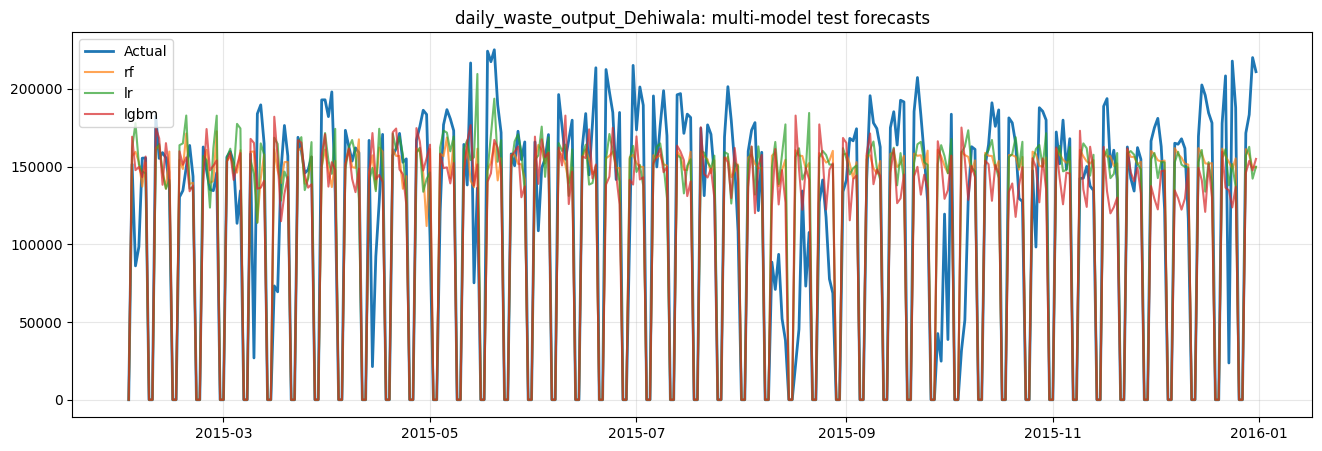

In [19]:
n = len(test_vals)
weekday_mean = pd.Series(train_vals).groupby(np.asarray(train_dates.dayofweek)).mean()
baselines = {
    "baseline: mean of training": np.full(n, train_vals.mean()),
    "baseline: same weekday last week": np.tile(train_vals[-7:], n // 7 + 1)[:n],
    "baseline: weekday average": weekday_mean.reindex(np.asarray(test_dates.dayofweek)).to_numpy(),
}

rows = {k: {kk: vv for kk, vv in r.items() if kk != "model_name"} for k, r in all_results.items()}
for k, p in baselines.items():
    rows[k] = scores(test_vals, p)

table = pd.DataFrame(rows).T.sort_values("rmse")
display(table.round(2))
table.to_csv(f"{OUTPUT_DIR}/multi_models_test_scores.csv")

plt.figure(figsize=(16, 5))
plt.plot(test_dates, test_vals, label="Actual", linewidth=2)
for label, p in all_preds.items():
    plt.plot(test_dates, p, label=label, alpha=0.7)
plt.legend(); plt.grid(alpha=0.3); plt.title(f"{DATASET_NAME}: multi-model test forecasts")
plt.savefig(f"{OUTPUT_DIR}/multi_models_forecast.png", dpi=150)
plt.show()